In [3]:
# ---- Imports -------------------------------------------------------------
import re, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 160)
RANDOM_STATE = 42          # one fixed seed for the split, CV folds and forest, so results are reproducible

# ---- Plot style: thin marks, light grid, fixed colour order -------------------------
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948")
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "axes.titleweight": "bold", "axes.titlesize": 11,
    "font.size": 9.5, "lines.linewidth": 2, "figure.dpi": 110})
DIVERGING = LinearSegmentedColormap.from_list("div", [ORANGE, "#f0efec", BLUE])

In [4]:
DATA_PATH = Path("Mobiles Dataset (2025).csv")
# Fallback only if the Kaggle file has not been placed next to the notebook:
# a public GitHub copy of the same file (used to test this notebook).
FALLBACK_URL = ("https://raw.githubusercontent.com/vipinchaudhary31122002/bytephone/main/"
                "dataset/Mobiles%20Dataset%20(2025).csv")
source = DATA_PATH if DATA_PATH.exists() else FALLBACK_URL
raw = pd.read_csv(source, encoding="latin-1")
print("Loaded from:", source)
raw.head()

Loaded from: https://raw.githubusercontent.com/vipinchaudhary31122002/bytephone/main/dataset/Mobiles%20Dataset%20(2025).csv


,Company Name,Model Name,Mobile Weight,RAM,Front Camera,Back Camera,Processor,Battery Capacity,Screen Size,Launched Price (Pakistan),Launched Price (India),Launched Price (China),Launched Price (USA),Launched Price (Dubai),Launched Year
0,Apple,iPhone 16 128GB,174g,6GB,12MP,48MP,A17 Bionic,"3,600mAh",6.1 inches,"PKR 224,999","INR 79,999","CNY 5,799",USD 799,"AED 2,799",2024
1,Apple,iPhone 16 256GB,174g,6GB,12MP,48MP,A17 Bionic,"3,600mAh",6.1 inches,"PKR 234,999","INR 84,999","CNY 6,099",USD 849,"AED 2,999",2024
2,Apple,iPhone 16 512GB,174g,6GB,12MP,48MP,A17 Bionic,"3,600mAh",6.1 inches,"PKR 244,999","INR 89,999","CNY 6,499",USD 899,"AED 3,199",2024
3,Apple,iPhone 16 Plus 128GB,203g,6GB,12MP,48MP,A17 Bionic,"4,200mAh",6.7 inches,"PKR 249,999","INR 89,999","CNY 6,199",USD 899,"AED 3,199",2024
4,Apple,iPhone 16 Plus 256GB,203g,6GB,12MP,48MP,A17 Bionic,"4,200mAh",6.7 inches,"PKR 259,999","INR 94,999","CNY 6,499",USD 949,"AED 3,399",2024


---
## Part 1 recap: concepts used throughout
| Concept | Meaning in this project |
|---|---|
| **Simple linear regression** | $\hat y = b_0 + b_1x$. Fits one straight line. The **intercept** $b_0$ is the predicted price when $x=0$. The **coefficient** $b_1$ is the change in predicted price for each 1-unit increase in $x$. |
| **Multiple linear regression** | $\hat y = b_0 + \sum_j b_j x_j$. Each $b_j$ is the effect of $x_j$ *with the other predictors held constant*. |
| **Polynomial regression** | Adds $x^2$ (and higher powers) as extra columns. The model is still *linear in its coefficients*, but it fits a curve. |
| **Train–test split** | The model learns from 80 % of the rows and is scored on the 20 % it never saw. This estimates performance on *new* phones. |
| **MAE** | Mean absolute error, in USD: the typical size of a miss. |
| **RMSE** | Root mean squared error, in USD. Squaring punishes large misses more, so RMSE ≥ MAE. A big gap between them means a few very large errors. |
| **R²** | Share of the variance in price that the model explains. 1 is perfect. 0 is no better than always predicting the mean. It can go negative on test data. |
| **Overfitting** | The model fits the training data much better than the test data, because it has learned noise rather than signal. |

In [ ]:
# inspect the dataset to understand its structure, including the number of rows and columns, as well as the data types of each column. This will help in identifying any necessary preprocessing steps before building a machine learning model.
print(f"Shape: {raw.shape[0]} rows × {raw.shape[1]} columns\n")
print(raw.dtypes.to_string())

Shape: 930 rows × 15 columns

Company Name                   str
Model Name                     str
Mobile Weight                  str
RAM                            str
Front Camera                   str
Back Camera                    str
Processor                      str
Battery Capacity               str
Screen Size                    str
Launched Price (Pakistan)      str
Launched Price (India)         str
Launched Price (China)         str
Launched Price (USA)           str
Launched Price (Dubai)         str
Launched Year                int64


In [6]:
# Missing values: NaN, plus text placeholders that pandas does not treat as missing
placeholder = raw.apply(lambda c: c.astype(str).str.strip().str.lower().isin(["not available", "na", "n/a", "-", ""]))
missing = pd.DataFrame({"NaN": raw.isna().sum(), "text placeholder": placeholder.sum()})
print(missing[missing.sum(axis=1) > 0] if missing.values.sum() else "No missing values")
print(f"\nExact duplicate rows: {raw.duplicated().sum()}")
raw[raw.duplicated(keep=False)].sort_values(["Company Name", "Model Name"]).head(6)

                           NaN  text placeholder
Launched Price (Pakistan)    0                 1

Exact duplicate rows: 15


,Company Name,Model Name,Mobile Weight,RAM,Front Camera,Back Camera,Processor,Battery Capacity,Screen Size,Launched Price (Pakistan),Launched Price (India),Launched Price (China),Launched Price (USA),Launched Price (Dubai),Launched Year
791,Infinix,Hot 10 Lite 64GB,195g,3GB,8MP,13MP,MediaTek Helio A25,"5,000mAh",6.6 inches,"PKR 19,999","INR 7,999",CNY 699,USD 109,AED 399,2020
798,Infinix,Hot 10 Lite 64GB,195g,3GB,8MP,13MP,MediaTek Helio A25,"5,000mAh",6.6 inches,"PKR 19,999","INR 7,999",CNY 699,USD 109,AED 399,2020
344,Oppo,A3 128GB,186g,4GB,5MP,50MP,Snapdragon 6s 4G Gen 1,5000mAh,6.7 inches,"PKR 59,999","INR 34,999","CNY 2,999",USD 399,"AED 1,499",2024
347,Oppo,A3 128GB,186g,4GB,5MP,50MP,Snapdragon 6s 4G Gen 1,5000mAh,6.7 inches,"PKR 59,999","INR 34,999","CNY 2,999",USD 399,"AED 1,499",2024
427,Oppo,K10 5G 128GB,205g,8GB,16MP,64MP + 8MP + 2MP,MediaTek Dimensity 8000-Max,"5,000mAh",6.59 inches,"PKR 64,999","INR 19,999","CNY 1,799",USD 249,"AED 1,300",2022
443,Oppo,K10 5G 128GB,205g,8GB,16MP,64MP + 8MP + 2MP,MediaTek Dimensity 8000-Max,"5,000mAh",6.59 inches,"PKR 64,999","INR 19,999","CNY 1,799",USD 249,"AED 1,300",2022


**What the inspection shows**
* Only `Launched Year` is numeric. Every other column is **text with units or currency codes** inside it: `"174g"`, `"3,600mAh"`, `"USD 1,099"`. These must be parsed into numbers before any regression is possible.
* Pandas reports almost no missing values, but one price cell holds the text `"Not available"`. Missing data is also *hidden* inside the text, for example models whose name omits the storage size.
* There are **15 exact duplicate rows**. If they stay in, the same phone can land in both the training and the test set, which inflates test scores. They will be removed.

---
## Step 5 (continued): Clean the data
Each rule below is written as a small function so it can be justified and re-used. We never invent target values.

| Raw column | Cleaned feature | Rule and justification |
|---|---|---|
| `Mobile Weight` | `weight_g` | Strip the "g". |
| `RAM` | `ram_gb` | First value. `"8GB / 12GB"` lists two variants; the first is the base model, which matches the listed price. |
| `Battery Capacity` | `battery_mah` | Remove the thousands comma and "mAh". |
| `Screen Size` | `screen_in` | First number = main or unfolded display. Foldables list two screens. |
| `Front Camera` | `front_cam_mp` | Highest MP value (`"Dual 32MP"` → 32). |
| `Back Camera` | `back_cam_max_mp`, `n_back_cams` | Main-sensor resolution and lens count. `"50MP + 8MP + 2MP"` → 50 and 3. |
| `Model Name` | `storage_gb` | Storage is written inside the name (`"iPhone 16 128GB"`; TB × 1024). If absent, the value is left **missing** and imputed later on training data only. |
| `Model Name`, `Screen Size` | `device_type` | `foldable` / `tablet` / `phone`. Foldables and tablets follow different pricing logic. |
| `Processor` (217 labels) | `chipset_family` | Grouped into about 9 families (Apple A, Snapdragon, Dimensity…). 217 sparse labels would overfit, and many labels appear only once. |
| `Company Name` | `brand` | Standardise case (`Poco`/`POCO`). |
| `Launched Price (USA)` | `price_usd` (**target**) | Accept only well-formed prices (`USD 1,099`). Malformed values become NaN and **the row is dropped**. |

In [7]:
NUM = r"(\d+(?:\.\d+)?)"

def first_num(s):
    # First number in a string, ignoring thousands commas ('3,600mAh' -> 3600.0)
    m = re.search(NUM, str(s).replace(",", ""))
    return float(m.group(1)) if m else np.nan

def mp_values(s):
    # All megapixel values in a camera string
    return [float(x) for x in re.findall(r"(\d+(?:\.\d+)?)\s*MP", str(s))]

def storage_from_name(name):
    m = re.findall(r"(\d+)\s*(GB|TB)\b", str(name), flags=re.I)
    if not m: return np.nan
    val, unit = m[-1]
    return float(val) * (1024 if unit.upper() == "TB" else 1)

def parse_usd(s):
    # Strict parser: accepts 'USD 1,099', 'USD 1719' or 'USD 799'. If commas are used, they must split
    # the number into groups of exactly 3 digits, so 'USD 396,22' is rejected as malformed.
    s = str(s).strip()
    if not re.fullmatch(r"USD\s*(?:\d{1,3}(?:,\d{3})+|\d+)(?:\.\d+)?", s):
        return np.nan                      # invalid -> missing target -> row removed later
    return float(s.replace("USD", "").replace(",", ""))

FOLD_PAT = r"Fold|Flip|Mate X|Razr|Find N|Magic V|\bOpen\b|Pocket|Galaxy W\d"
TAB_PAT  = r"\bPad\b|iPad|MatePad|\bTab\b|Tablet"
def device_type(row):
    name, screen = str(row["Model Name"]), str(row["Screen Size"])
    if re.search(FOLD_PAT, name, re.I) or re.search(r"unfolded|internal|external", screen, re.I):
        return "foldable"
    if re.search(TAB_PAT, name, re.I) or first_num(screen) >= 7.5:
        return "tablet"
    return "phone"

def chipset_family(p):
    p = str(p)
    rules = [("Apple A-series", r"Bionic|^A\d+"), ("Snapdragon", r"Snapdragon"),
             ("Dimensity", r"Dimensity"), ("Helio/MediaTek other", r"Helio|MediaTek|MT\d|^G\d"),
             ("Exynos", r"Exynos"), ("Kirin", r"Kirin"), ("Google Tensor", r"Tensor"),
             ("Unisoc", r"Unisoc|Spreadtrum|^T\d{3}")]
    for fam, pat in rules:
        if re.search(pat, p, re.I): return fam
    return "Other"

In [8]:
df = raw.drop_duplicates().copy()           # 1) remove the 15 exact duplicates
print(f"After removing duplicates: {len(df)} rows")

clean = pd.DataFrame({
    "brand":           df["Company Name"].str.strip().replace({"Poco": "POCO"}),
    "model":           df["Model Name"].str.strip(),               # kept only as an ID, never a predictor
    "launched_year":   df["Launched Year"].astype(int),
    "ram_gb":          df["RAM"].map(first_num),
    "storage_gb":      df["Model Name"].map(storage_from_name),
    "weight_g":        df["Mobile Weight"].map(first_num),
    "battery_mah":     df["Battery Capacity"].map(first_num),
    "screen_in":       df["Screen Size"].map(first_num),
    "front_cam_mp":    df["Front Camera"].map(lambda s: max(mp_values(s), default=np.nan)),
    "back_cam_max_mp": df["Back Camera"].map(lambda s: max(mp_values(s), default=np.nan)),
    "n_back_cams":     df["Back Camera"].map(lambda s: len(mp_values(s)) or np.nan),
    "device_type":     df.apply(device_type, axis=1),
    "chipset_family":  df["Processor"].map(chipset_family),
    "price_usd":       df["Launched Price (USA)"].map(parse_usd),
}, index=df.index)

# Other-country prices are kept aside for the leakage check only (Step 6)
other_prices = df[[c for c in df.columns if c.startswith("Launched Price") and "USA" not in c]] \
                 .apply(lambda col: col.map(first_num))

bad_target = clean["price_usd"].isna()
print(f"Invalid / missing USD prices: {bad_target.sum()}")
df.loc[bad_target, ["Company Name", "Model Name", "Launched Price (USA)", "Launched Price (India)", "Launched Price (Dubai)"]]

After removing duplicates: 915 rows
Invalid / missing USD prices: 1


,Company Name,Model Name,Launched Price (USA),Launched Price (India),Launched Price (Dubai)
685,Nokia,T21,"USD 396,22","INR 17,999",AED 870


**The one invalid target.** The Nokia T21 is listed at `"USD 396,22"`. Read naively, this becomes **$39,622**, roughly 15× the most expensive foldable. A comma is not a valid thousands separator for a 2-digit group, so the value is malformed. Its own Indian (₹17,999 ≈ $215) and Dubai (AED 870 ≈ $237) prices suggest neither 39,622 nor 396.22 is right. We cannot tell the true value, and the brief says not to invent target values, so **the row is dropped**. If we kept it, that single point would dominate the squared-error loss and wreck the linear models.

In [9]:
clean = clean.loc[~bad_target].copy()
other_prices = other_prices.loc[clean.index]

# Sanity rules on the parsed numbers: physically impossible values -> NaN (imputed later)
rules = {"weight_g": (80, 1000), "ram_gb": (0.5, 32), "battery_mah": (1000, 15000),
         "screen_in": (3, 15), "launched_year": (2010, 2026)}
for col, (lo, hi) in rules.items():
    bad = ~clean[col].between(lo, hi) & clean[col].notna()
    clean.loc[bad, col] = np.nan
    print(f"{col:15s} out-of-range values set to NaN: {bad.sum()}")

print(f"\nDuplicates after cleaning: {clean.drop(columns='model').duplicated().sum()} "
      "(same spec + price, different model name; kept, because these are genuinely different products)")
print(f"Final cleaned data: {clean.shape}")
print("\nMissing values after parsing:"); print(clean.isna().sum()[lambda s: s > 0].to_string())

weight_g        out-of-range values set to NaN: 0
ram_gb          out-of-range values set to NaN: 0


battery_mah     out-of-range values set to NaN: 0
screen_in       out-of-range values set to NaN: 0
launched_year   out-of-range values set to NaN: 0

Duplicates after cleaning: 24 (same spec + price, different model name; kept, because these are genuinely different products)
Final cleaned data: (914, 14)

Missing values after parsing:
storage_gb    151


In [10]:
print(clean["device_type"].value_counts().to_string()); print()
print(clean["chipset_family"].value_counts().to_string()); print()
# Manual check of the rule-based device labels
print("Foldables:", ", ".join(clean.loc[clean.device_type == "foldable", "model"].str.replace(r"\s\d+(GB|TB)$", "", regex=True).unique()))
print("\nTablets:", ", ".join(clean.loc[clean.device_type == "tablet", "model"].str.replace(r"\s\d+(GB|TB)$", "", regex=True).unique()[:40]), "...")

device_type
phone       776
tablet      100
foldable     38

chipset_family
Snapdragon              363
Dimensity               209
Helio/MediaTek other    120
Apple A-series           97
Exynos                   47
Unisoc                   33
Kirin                    31
Google Tensor            13
Other                     1

Foldables: Galaxy Z Fold 5, Galaxy Z Flip 5, Galaxy Z Fold 4, Galaxy Z Flip 4, Galaxy W22 5G, Galaxy W21 5G, OnePlus Open, Find N3, Find N3 Flip, Find N2 Flip, Find N2, Razr, Razr 50 Ultra, Razr 50, P50 Pocket, Mate X2, Mate Xs 2, Mate X3, Mate X6, Mate XT, Pixel 9 Pro Fold, Phantom V Fold2, Phantom V Flip2, Zero Flip, Magic V, Magic Vs, Magic V2, Magic V3, Galaxy Z Fold6

Tablets: iPad Air 10.9-inch, iPad 10.2-inch, iPad Mini 7.9-inch, iPad Pro 11-inch, iPad Pro 12.9-inch, iPad Pro 13-inch, Galaxy Tab S9 Ultra, Galaxy Tab S9+, Galaxy Tab S9, Galaxy Tab S9 FE, Galaxy Tab S8 Ultra, Galaxy Tab S8+, Galaxy Tab S8, Galaxy Tab A9+, Galaxy Tab A9, Galaxy Tab A8, Galaxy

**How missing data is treated.** `storage_gb` is missing for about 16 % of rows (mostly Huawei, OnePlus tablets and older models whose names omit storage). Possible treatments:
* *Drop the rows.* This would lose about 150 phones and bias the sample against certain brands.
* *Impute the median.* Chosen. The median is robust to the right-skew of storage (64 → 1024 GB).
* We also add a **missing-indicator** flag (`SimpleImputer(add_indicator=True)`). If "storage not stated" is itself related to price, the model can learn that.

The imputer is **fitted on the training rows only** (Step 6), so no information from the test set leaks into it.

### Outliers: check them, then decide
We use the 1.5 × IQR rule to *flag* unusually priced devices, then look at what they are before deciding anything.

In [11]:
q1, q3 = clean["price_usd"].quantile([.25, .75]); iqr = q3 - q1
upper = q3 + 1.5 * iqr
out = clean[clean["price_usd"] > upper]
print(f"IQR fence: > ${upper:,.0f}  ->  {len(out)} flagged devices")
print(out["device_type"].value_counts().to_string())
out.sort_values("price_usd", ascending=False)[["brand", "model", "device_type", "ram_gb", "storage_gb", "price_usd"]].head(8)

IQR fence: > $1,719  ->  19 flagged devices
device_type
foldable    17
tablet       1
phone        1


,brand,model,device_type,ram_gb,storage_gb,price_usd
661,Huawei,Mate XT 512GB,foldable,12.0,512.0,2799.0
630,Huawei,Mate X2,foldable,8.0,NaN,2699.0
660,Huawei,Mate XT 256GB,foldable,12.0,256.0,2599.0
657,Huawei,Mate X6,foldable,12.0,NaN,2499.0
643,Huawei,Mate X3,foldable,12.0,NaN,2499.0
634,Huawei,Mate Xs 2,foldable,8.0,NaN,2499.0
929,Samsung,Galaxy Z Fold6 1TB,foldable,12.0,1024.0,2259.0
858,Honor,Magic V2,foldable,12.0,NaN,1899.0


**Decision: keep the flagged devices.** Every flagged device is a real premium product: foldables, Pro/Ultra flagships with 1 TB storage, and large tablets. Their prices are genuine, not errors. Removing them would make the test set look easier than the real market and would hide where the models fail. The only value we removed was the *malformed* Nokia price above. The skew will be handled by modelling choices instead: a log-target extension in Step 7 and robust metrics (MAE alongside RMSE).

---
## Step 6: Explore the data

In [12]:
clean.drop(columns="model").describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
launched_year,914.0,2022.2,1.9,2014.0,2021.0,2023.0,2024.0,2025.0
ram_gb,914.0,7.8,3.2,1.0,6.0,8.0,8.0,16.0
storage_gb,763.0,213.6,156.4,16.0,128.0,128.0,256.0,2048.0
weight_g,914.0,228.7,105.9,135.0,185.0,194.5,209.0,732.0
battery_mah,914.0,5026.8,1362.3,2000.0,4400.0,5000.0,5100.0,11200.0
screen_in,914.0,7.1,1.5,5.0,6.5,6.7,6.8,14.6
front_cam_mp,914.0,18.2,12.0,2.0,8.0,16.0,32.0,60.0
back_cam_max_mp,914.0,46.6,31.1,5.0,16.0,50.0,50.0,200.0
n_back_cams,914.0,1.6,0.8,1.0,1.0,1.0,2.0,4.0
price_usd,914.0,589.0,422.3,79.0,269.0,449.0,849.0,2799.0


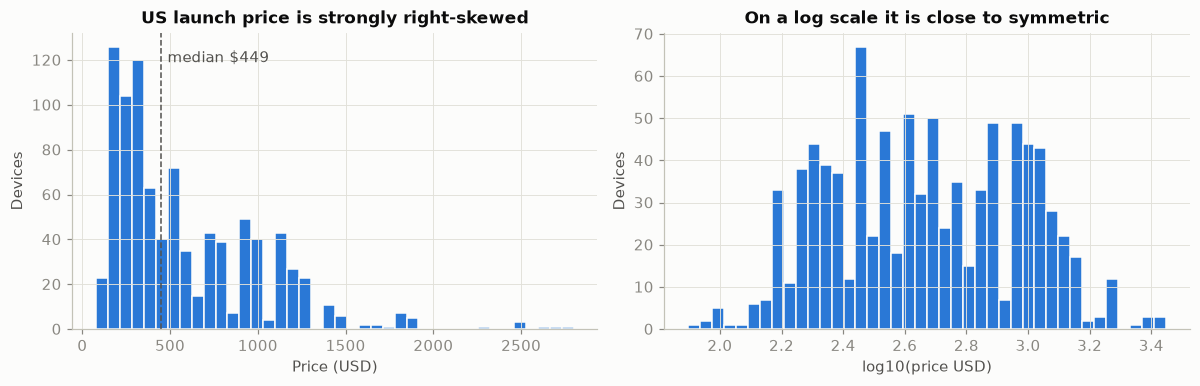

Skewness: raw = 1.47, log = 0.05


In [13]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(clean["price_usd"], bins=40, color=BLUE, edgecolor="#fcfcfb", linewidth=1)
ax[0].axvline(clean["price_usd"].median(), color=INK2, lw=1, ls="--")
ax[0].text(clean["price_usd"].median()*1.08, ax[0].get_ylim()[1]*.9, f"median ${clean['price_usd'].median():,.0f}", color=INK2)
ax[0].set(title="US launch price is strongly right-skewed", xlabel="Price (USD)", ylabel="Devices")
ax[1].hist(np.log10(clean["price_usd"]), bins=40, color=BLUE, edgecolor="#fcfcfb", linewidth=1)
ax[1].set(title="On a log scale it is close to symmetric", xlabel="log10(price USD)", ylabel="Devices")
plt.tight_layout(); plt.show()
print(f"Skewness: raw = {clean['price_usd'].skew():.2f}, log = {np.log(clean['price_usd']).skew():.2f}")

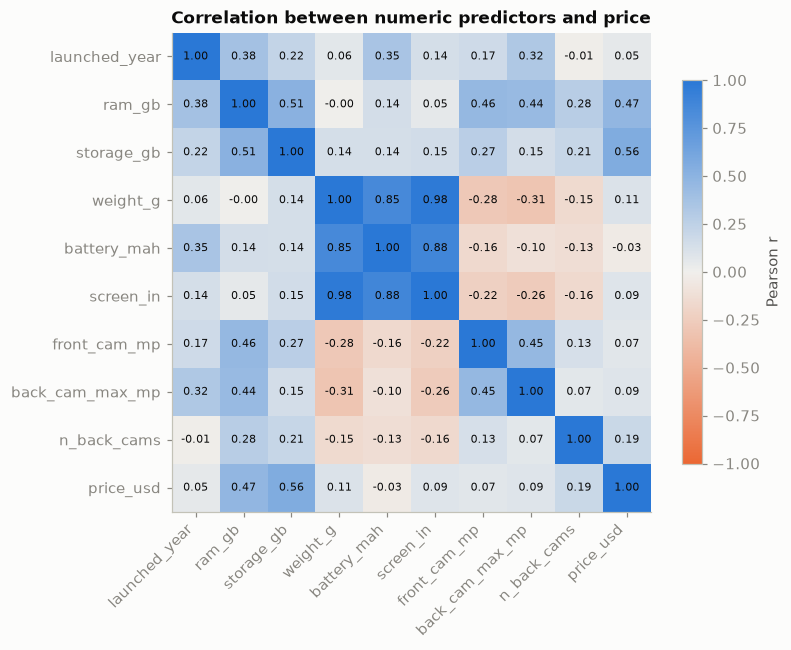

In [14]:
num_cols = ["launched_year", "ram_gb", "storage_gb", "weight_g", "battery_mah",
            "screen_in", "front_cam_mp", "back_cam_max_mp", "n_back_cams"]
corr = clean[num_cols + ["price_usd"]].corr()
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right"); ax.set_yticks(range(len(corr)), corr.columns)
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7.5, color=INK)
fig.colorbar(im, shrink=.8, label="Pearson r")
ax.set_title("Correlation between numeric predictors and price")
plt.tight_layout(); plt.show()

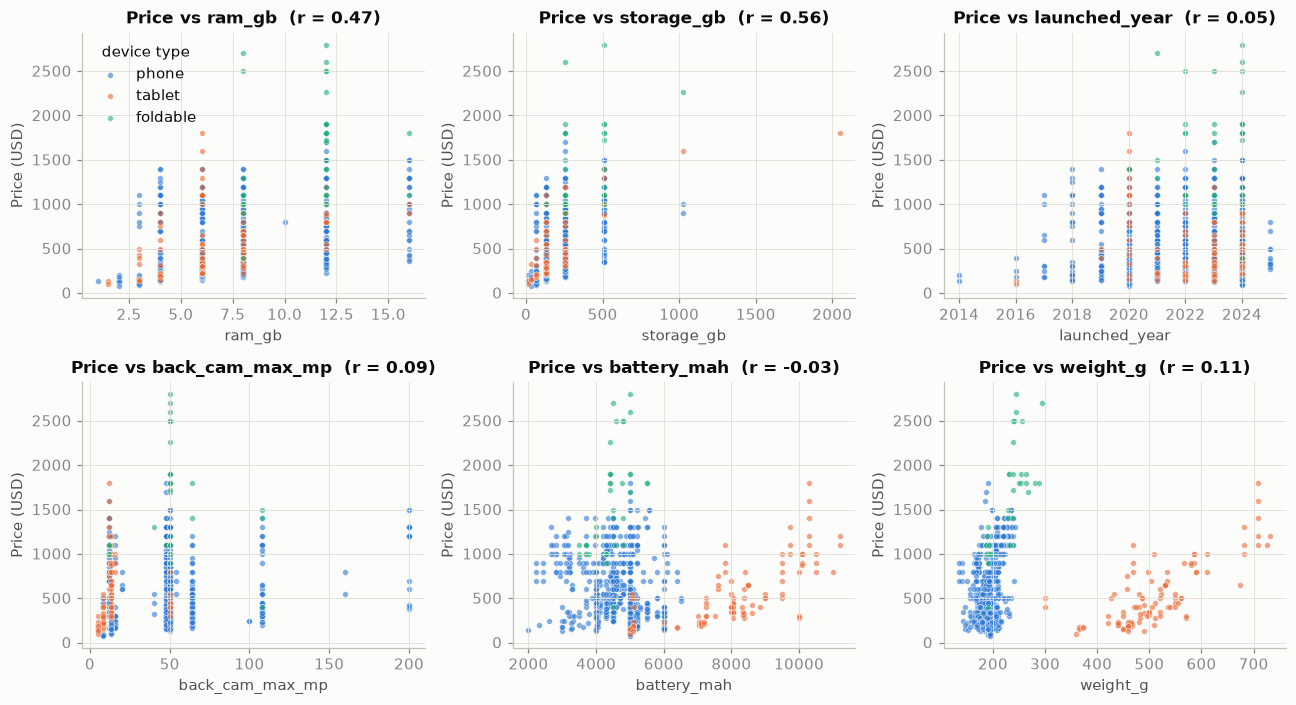

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6.5))
colors = {"phone": BLUE, "tablet": ORANGE, "foldable": AQUA}
for ax, col in zip(axes.ravel(), ["ram_gb", "storage_gb", "launched_year", "back_cam_max_mp", "battery_mah", "weight_g"]):
    for t, c in colors.items():
        s = clean[clean["device_type"] == t]
        ax.scatter(s[col], s["price_usd"], s=14, alpha=.6, color=c, label=t, edgecolors="#fcfcfb", linewidths=.4)
    ax.set(xlabel=col, ylabel="Price (USD)", title=f"Price vs {col}  (r = {clean[col].corr(clean['price_usd']):.2f})")
axes[0, 0].legend(frameon=False, title="device type")
plt.tight_layout(); plt.show()

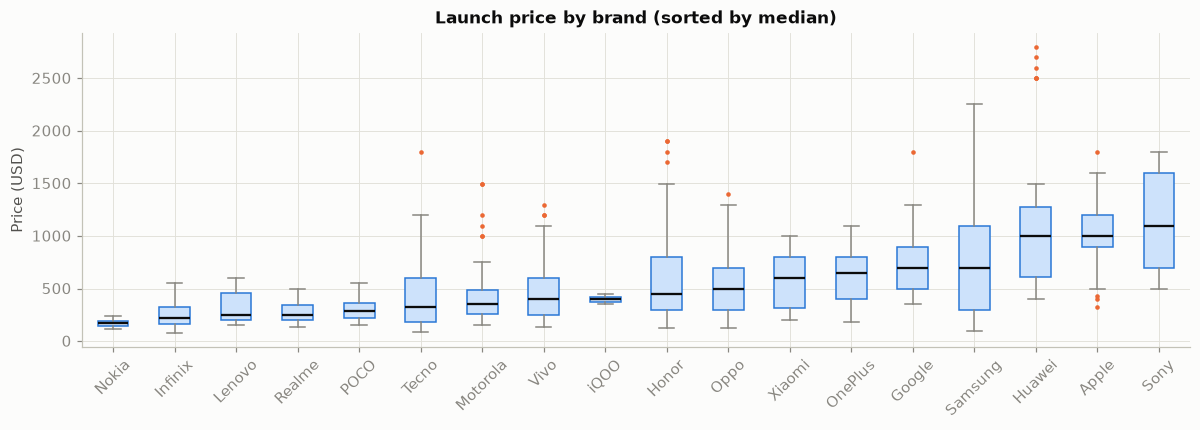

,count,median,mean
device_type,,,
foldable,38,1599.0,1588.0
phone,776,429.0,547.0
tablet,100,439.0,539.0


In [16]:
order = clean.groupby("brand")["price_usd"].median().sort_values().index
fig, ax = plt.subplots(figsize=(11, 4))
ax.boxplot([clean.loc[clean.brand == b, "price_usd"] for b in order], tick_labels=order, patch_artist=True,
           boxprops=dict(facecolor="#cde2fb", edgecolor=BLUE), medianprops=dict(color=INK, lw=1.5),
           whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED),
           flierprops=dict(marker="o", markersize=3, markerfacecolor=ORANGE, markeredgecolor="none"))
ax.set(title="Launch price by brand (sorted by median)", ylabel="Price (USD)"); ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()
clean.groupby("device_type")["price_usd"].agg(["count", "median", "mean"]).round(0)

**What the exploration tells us (and how it shapes the modelling)**
* **Price is right-skewed.** Most devices cost under $600 and a long tail runs to $2,800. Linear models fitted with squared error will chase the tail. This motivates reporting MAE alongside RMSE and trying a log-transformed target.
* **RAM and storage are the strongest single numeric predictors.** Their relationships look curved and fan out (variance grows with price), which a straight line cannot fully capture. This is the motivation for polynomial regression.
* **Brand and device type matter a lot.** Apple, Google, Samsung and Huawei price far above Infinix, Tecno and POCO at similar specs, and foldables sit in their own price band. Specs alone will leave a lot of error, so categorical encoding is needed.
* **Some predictors are correlated with each other** (weight, screen and battery all mark tablets). This multicollinearity makes individual MLR coefficients unstable, but it does not harm predictive accuracy.

### Separate predictors from the target and remove leakage
**Leakage variables** are columns that would not be known at prediction time, or that are just another form of the target.
* `Launched Price (Pakistan / India / China / Dubai)` are the *same launch decision* converted into other currencies. The correlation check below shows they track the USD price almost perfectly. Using them would produce a near-perfect but useless model: if you already know the Indian price, you are not predicting anything. **They are removed.**
* `model` (the model name) is a unique identifier. It cannot generalise to a new phone, so it is **removed** after we extracted storage from it.

In [17]:
leak = other_prices.corrwith(clean["price_usd"]).rename("r with USD price").round(3)
print(leak.to_string())

Launched Price (Pakistan)    0.897
Launched Price (India)       0.969
Launched Price (China)       0.968
Launched Price (Dubai)       0.991


In [18]:
TARGET = "price_usd"
NUM_FEATURES = num_cols
CAT_FEATURES = ["brand", "chipset_family", "device_type"]

X = clean[NUM_FEATURES + CAT_FEATURES]      # leakage columns and the model name are NOT included
y = clean[TARGET]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE)
print(f"Train: {X_train.shape}   Test: {X_test.shape}")
print(f"Mean price  train ${y_train.mean():,.0f}  |  test ${y_test.mean():,.0f}")
print("Device types in test:", X_test["device_type"].value_counts().to_dict())

Train: (731, 12)   Test: (183, 12)
Mean price  train $582  |  test $616
Device types in test: {'phone': 150, 'tablet': 25, 'foldable': 8}


### Preprocessing pipeline (fitted on the training data only)
A `ColumnTransformer` inside a `Pipeline` guarantees that the imputation medians, scaling means and standard deviations, and one-hot categories are **learned from `X_train` only**. When we call `.predict(X_test)`, those learned values are simply *applied* to the test rows.
* **Numeric:** median imputation + missing indicator, then `StandardScaler`. Scaling does not change OLS predictions, but it puts the coefficients on a comparable scale ("effect of a 1-SD increase"), and polynomial terms need it to stay numerically stable.
* **Categorical:** most-frequent imputation, then `OneHotEncoder(drop="first")`. Dropping one level avoids perfect collinearity with the intercept (the dummy-variable trap). `handle_unknown="ignore"` protects against a brand that appears only in the test set.

In [19]:
numeric_pipe = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                         ("scale", StandardScaler())])
categorical_pipe = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                             ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False))])
preprocess = ColumnTransformer([("num", numeric_pipe, NUM_FEATURES),
                                ("cat", categorical_pipe, CAT_FEATURES)])

# Show what the fitted preprocessor produces (fitted on TRAIN only)
Xt = preprocess.fit_transform(X_train)
print(f"{X_train.shape[1]} raw predictors -> {Xt.shape[1]} model columns after imputation flags + one-hot encoding")

12 raw predictors -> 37 model columns after imputation flags + one-hot encoding


---
## Step 7: Build and compare models
### Shared evaluation helper
Every model is scored on **the same 183 held-out test rows**. To see generalisation more robustly, we also run 5-fold cross-validation on the training set only.

In [20]:
results, test_preds, fitted = [], {}, {}
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def metrics(y_true, y_pred):
    return dict(MAE=mean_absolute_error(y_true, y_pred),
                RMSE=np.sqrt(mean_squared_error(y_true, y_pred)),
                R2=r2_score(y_true, y_pred))

def evaluate(name, model, features, note=""):
    model.fit(X_train[features], y_train)
    tr = metrics(y_train, model.predict(X_train[features]))
    p = model.predict(X_test[features]); te = metrics(y_test, p)
    cvs = cross_validate(model, X_train[features], y_train, cv=cv, scoring="neg_root_mean_squared_error")
    results.append({"Model": name, "Predictors": note or ", ".join(features),
                    "Train MAE": tr["MAE"], "Train RMSE": tr["RMSE"], "Train R²": tr["R2"],
                    "Test MAE": te["MAE"], "Test RMSE": te["RMSE"], "Test R²": te["R2"],
                    "CV RMSE (5-fold, train)": -cvs["test_score"].mean(),
                    "CV RMSE SE": cvs["test_score"].std(ddof=1) / np.sqrt(len(cvs["test_score"]))})
    test_preds[name] = p; fitted[name] = model
    print(f"{name:38s} test MAE ${te['MAE']:,.0f} | RMSE ${te['RMSE']:,.0f} | R² {te['R2']:.3f}   (train R² {tr['R2']:.3f})")
    return model

### 7a. Simple linear regression: choosing the single predictor
We choose the predictor using the **training data only** (its correlation with price). Choosing it with the test set would be a subtle form of leakage.

In [21]:
train_corr = X_train[NUM_FEATURES].corrwith(y_train).abs().sort_values(ascending=False)
print(train_corr.round(3).to_string())
SLR_FEATURE = train_corr.index[0]
print(f"\nChosen single predictor: {SLR_FEATURE}")

storage_gb         0.582
ram_gb             0.486
n_back_cams        0.189
weight_g           0.120
screen_in          0.103
back_cam_max_mp    0.090
launched_year      0.076
front_cam_mp       0.075
battery_mah        0.017

Chosen single predictor: storage_gb


In [22]:
slr = Pipeline([("impute", SimpleImputer(strategy="median")), ("lr", LinearRegression())])
evaluate(f"1. Simple linear ({SLR_FEATURE})", slr, [SLR_FEATURE])
b0, b1 = slr.named_steps["lr"].intercept_, slr.named_steps["lr"].coef_[0]
print(f"\nFitted line:  price = {b0:,.1f} + {b1:,.1f} × {SLR_FEATURE}")

1. Simple linear (storage_gb)          test MAE $310 | RMSE $427 | R² 0.100   (train R² 0.233)

Fitted line:  price = 289.1 + 1.5 × storage_gb


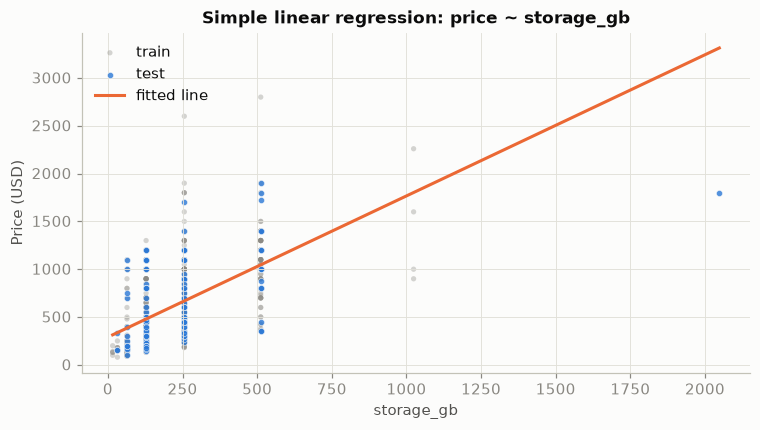

In [23]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(X_train[SLR_FEATURE], y_train, s=12, alpha=.35, color=MUTED, label="train", edgecolors="none")
ax.scatter(X_test[SLR_FEATURE], y_test, s=16, alpha=.8, color=BLUE, label="test", edgecolors="#fcfcfb", linewidths=.4)
xs = np.linspace(X[SLR_FEATURE].min(), X[SLR_FEATURE].max(), 200)
ax.plot(xs, slr.predict(pd.DataFrame({SLR_FEATURE: xs})), color=ORANGE, label="fitted line")
ax.set(title=f"Simple linear regression: price ~ {SLR_FEATURE}", xlabel=SLR_FEATURE, ylabel="Price (USD)")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

**Interpreting the simple linear model**
* **Predictor → target:** `storage_gb` → `price_usd`. Storage was chosen because it has the highest correlation with price *in the training set* (r ≈ 0.58).
* **Intercept ($289):** the predicted price of a phone with 0 GB storage. This is an extrapolation with no physical meaning. Its job is to anchor the line.
* **Coefficient (+$1.5 per GB):** each extra GB adds about $1.50 to the predicted price. Moving from 128 GB to 256 GB therefore adds about **$192**.
* **Fit:** train R² = 0.23 and test R² = 0.10. Test MAE is **$310**, about half the average test price ($616). Storage alone explains very little. The plot shows why: at 128 GB and 256 GB, prices range from under $200 to over $1,500, because a budget Infinix and a flagship Samsung can have the same storage.
* **Why is test R² lower than train R²?** This is not overfitting, because a 2-parameter line cannot memorise anything. The test set happens to hold more foldables (8 vs about 30 across 731 training rows), and storage is often missing for them. The model is **underfitting**: high bias, too simple for the problem.

### 7b. Multiple linear regression: all specifications + brand + device type

In [24]:
mlr = Pipeline([("prep", preprocess), ("lr", LinearRegression())])
evaluate("2. Multiple linear (all predictors)", mlr, NUM_FEATURES + CAT_FEATURES, note="9 numeric + brand, chipset, device type")

names = mlr.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(mlr.named_steps["lr"].coef_, index=names).rename(lambda s: s.split("__")[1])
print(f"\nIntercept (reference brand/device, all numeric at train mean): ${mlr.named_steps['lr'].intercept_:,.0f}")
print("\nNumeric coefficients (USD per +1 standard deviation, other predictors held constant):")
print(coefs[[c for c in coefs.index if c in NUM_FEATURES]].sort_values().round(0).to_string())
print("\nLargest categorical effects (USD vs reference level):")
cat = coefs[[c for c in coefs.index if c not in NUM_FEATURES and not c.startswith("missingindicator")]]
print(pd.concat([cat.nsmallest(4), cat.nlargest(6)]).round(0).to_string())

2. Multiple linear (all predictors)    test MAE $141 | RMSE $189 | R² 0.824   (train R² 0.794)

Intercept (reference brand/device, all numeric at train mean): $1,744

Numeric coefficients (USD per +1 standard deviation, other predictors held constant):
battery_mah        -78.0
front_cam_mp       -27.0
n_back_cams         -9.0
launched_year        3.0
screen_in           10.0
back_cam_max_mp     19.0
storage_gb          51.0
ram_gb             178.0
weight_g           270.0

Largest categorical effects (USD vs reference level):
device_type_tablet             -1295.0
device_type_phone               -631.0
chipset_family_Google Tensor    -475.0
brand_iQOO                      -453.0
brand_Sony                       390.0
brand_Huawei                     199.0
brand_Google                      39.0
brand_Honor                      -69.0
brand_Samsung                   -107.0
brand_Vivo                      -160.0


**Interpreting the multiple linear model**
* **Test MAE falls from $310 to $141 and R² rises from 0.10 to 0.82.** Adding brand, device type, chipset and the other specs explains most of the price variation.
* **Train R² (0.79) ≈ test R² (0.82):** no sign of overfitting. The test score is even slightly higher, which is normal sampling noise with 183 test rows.
* **Reading the coefficients.** Numeric predictors are standardised, so each coefficient is the price change for a **+1 standard-deviation** change *with all other predictors held constant*.
  * **RAM: +$178 per SD (≈ 3.2 GB), so roughly +$55 per GB.** This is the clearest hardware effect.
  * **Device type:** relative to the reference category (*foldable*), a phone is about $630 cheaper and a tablet about $1,300 cheaper at equal specs. This is the biggest single effect in the model.
  * **Brand** (reference = Apple): Sony (+$390) and Huawei (+$199) price *above* Apple at equal specs. Samsung (−$107) and Vivo (−$160) price below. Brand acts as a proxy for market positioning.
* **Caution: multicollinearity.** `weight_g`, `screen_in` and `battery_mah` correlate at 0.85–0.98 (heatmap). Their individual coefficients are unstable and partly cancel out: weight gets **+$270** while battery gets **−$78**. *This does not mean heavier phones cost more and bigger batteries cost less.* The three variables together mostly separate tablets from phones. The coefficients are fine for **prediction** but should not be read causally. Effects of small categories (such as iQOO, with only 3 devices) are also unreliable.

### 7c. Polynomial regression (degree 2) vs linear, same predictor, same split
To make the comparison fair, the only thing that changes is the $x^2$ term. Predictor, split and imputation are identical to model 1.

3. Polynomial deg 2 (storage_gb)       test MAE $309 | RMSE $425 | R² 0.109   (train R² 0.242)


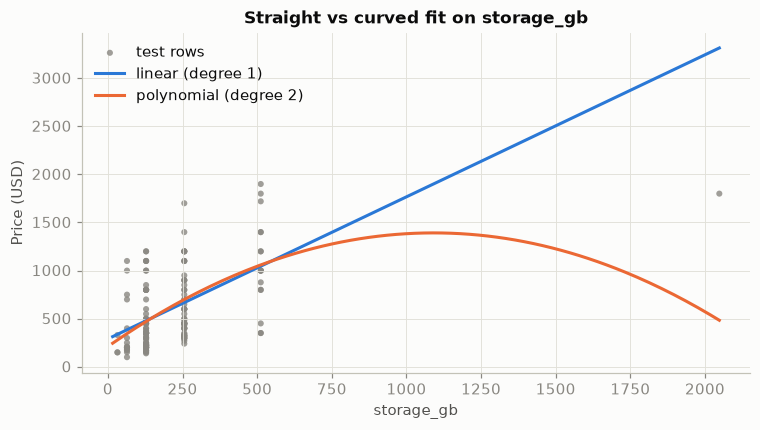

In [25]:
poly2 = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler()),
                  ("poly", PolynomialFeatures(degree=2, include_bias=False)), ("lr", LinearRegression())])
evaluate(f"3. Polynomial deg 2 ({SLR_FEATURE})", poly2, [SLR_FEATURE])

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(X_test[SLR_FEATURE], y_test, s=16, alpha=.8, color=MUTED, label="test rows", edgecolors="none")
grid = pd.DataFrame({SLR_FEATURE: xs})
ax.plot(xs, slr.predict(grid), color=BLUE, label="linear (degree 1)")
ax.plot(xs, poly2.predict(grid), color=ORANGE, label="polynomial (degree 2)")
ax.set(title=f"Straight vs curved fit on {SLR_FEATURE}", xlabel=SLR_FEATURE, ylabel="Price (USD)")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

#### Overfitting experiment: what happens as the degree increases?
For degrees 1–8 we compare training RMSE with 5-fold cross-validated RMSE, using **training data only** (the test set stays untouched). Overfitting shows up as training error that keeps falling while validation error flattens or rises.

        train RMSE  CV RMSE  CV RMSE sd
degree                                 
1            362.7    362.7        27.8
2            360.4    362.0        27.1
3            360.2    362.1        27.1
4            359.1    361.2        26.7
5            359.0    361.4        26.5
6            359.0    361.4        26.5
7            359.0    361.4        26.5
8            359.0    361.4        26.5


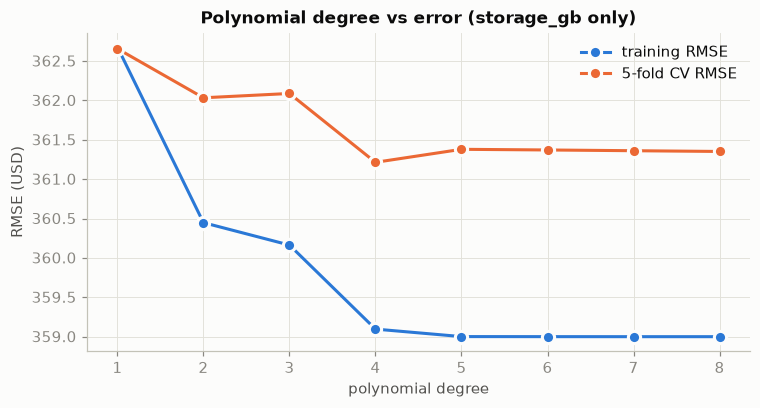

In [26]:
rows = []
for d in range(1, 9):
    m = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler()),
                  ("poly", PolynomialFeatures(degree=d, include_bias=False)), ("lr", LinearRegression())])
    r = cross_validate(m, X_train[[SLR_FEATURE]], y_train, cv=cv, scoring="neg_root_mean_squared_error",
                       return_train_score=True)
    rows.append({"degree": d, "train RMSE": -r["train_score"].mean(), "CV RMSE": -r["test_score"].mean(),
                 "CV RMSE sd": r["test_score"].std()})
deg = pd.DataFrame(rows).set_index("degree")
print(deg.round(1).to_string())

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(deg.index, deg["train RMSE"], "-o", color=BLUE, ms=8, label="training RMSE", mec="#fcfcfb", mew=2)
ax.plot(deg.index, deg["CV RMSE"], "-o", color=ORANGE, ms=8, label="5-fold CV RMSE", mec="#fcfcfb", mew=2)
ax.set(title=f"Polynomial degree vs error ({SLR_FEATURE} only)", xlabel="polynomial degree", ylabel="RMSE (USD)")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

**Straight vs curved fit, and what this says about overfitting**
* With `storage_gb` as the only predictor, the degree-2 model barely changes anything: test RMSE **$425 vs $427**, R² **0.109 vs 0.100**. The curve bends slightly upward, so each GB is worth a little more at high capacities, but the gain is negligible.
* **Raising the degree does not help either.** Cross-validated RMSE stays at about $361–363 from degree 1 to 8, and training RMSE drops only $4. Storage takes about 10 distinct values (16, 32 … 2048 GB). Most of the error comes from *different devices at the same storage level*, not from curvature that a polynomial could capture. **No amount of flexibility in one variable fixes a model that is missing the important variables.** This is a bias problem, not a variance problem.
* **Where overfitting *does* appear:** the two flexible extension models in 7d. The all-predictor degree-2 model (92 columns) has train RMSE $147 vs test RMSE $188, a **$41 gap**. The random forest has a gap of about $84 (train R² 0.96 vs test 0.87). Both still generalise better than plain MLR, but they have memorised part of the training data.

### 7d. Extensions beyond the required models
These go beyond the brief. They test *why* the linear models make errors rather than just reporting that they do.
1. **MLR on log(price).** The EDA showed price is right-skewed and its spread grows with price. Modelling `log(price)` turns those effects into percentages ("Apple adds about X % to price"), which fits how pricing actually works. Predictions are transformed back to USD, so the metrics stay comparable.
2. **Random forest (benchmark).** A non-linear, interaction-aware reference point. It tells us how much accuracy the linear form leaves on the table.

In [27]:
mlr_log = TransformedTargetRegressor(regressor=Pipeline([("prep", preprocess), ("lr", LinearRegression())]),
                                     func=np.log, inverse_func=np.exp)
evaluate("4. Multiple linear on log(price) [ext.]", mlr_log, NUM_FEATURES + CAT_FEATURES, note="as model 2, target log-transformed")

rf = Pipeline([("prep", preprocess), ("rf", RandomForestRegressor(n_estimators=400, min_samples_leaf=2,
                                                                  random_state=RANDOM_STATE, n_jobs=-1))])
evaluate("5. Random forest [benchmark]", rf, NUM_FEATURES + CAT_FEATURES, note="as model 2");

4. Multiple linear on log(price) [ext.] test MAE $144 | RMSE $223 | R² 0.755   (train R² 0.767)
5. Random forest [benchmark]           test MAE $98 | RMSE $164 | R² 0.867   (train R² 0.962)


**Leakage demonstration (not a valid model, shown only to justify removing the other-currency prices).** Adding the Dubai price to model 2 gives the "accuracy" below. This is exactly the kind of result that would look impressive and be meaningless.

In [28]:
X_leak_tr = X_train.assign(aed=other_prices.loc[X_train.index, "Launched Price (Dubai)"])
X_leak_te = X_test.assign(aed=other_prices.loc[X_test.index, "Launched Price (Dubai)"])
leak_prep = ColumnTransformer([("num", numeric_pipe, NUM_FEATURES + ["aed"]), ("cat", categorical_pipe, CAT_FEATURES)])
leaky = Pipeline([("prep", leak_prep), ("lr", LinearRegression())]).fit(X_leak_tr, y_train)
print("Leaky model test metrics:", {k: round(v, 3) for k, v in metrics(y_test, leaky.predict(X_leak_te)).items()})

Leaky model test metrics: {'MAE': 33.28, 'RMSE': np.float64(51.981), 'R2': 0.987}


3. **Degree-2 polynomial on *all* numeric predictors (overfitting stress test).** This adds every squared term and every pairwise interaction: 9 numeric predictors (+1 missing flag) become 65 columns, plus the dummies. With only 730 training rows, this is where overfitting should become visible.

In [29]:
poly_prep = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)), ("scale", StandardScaler()),
                      ("poly", PolynomialFeatures(degree=2, include_bias=False))]), NUM_FEATURES),
    ("cat", categorical_pipe, CAT_FEATURES)])
poly_all = Pipeline([("prep", poly_prep), ("lr", LinearRegression())])
evaluate("6. Polynomial deg 2, all predictors [ext.]", poly_all, NUM_FEATURES + CAT_FEATURES,
         note="all squares + interactions of numeric, plus dummies")
print("Model columns:", poly_all.named_steps["prep"].transform(X_train.iloc[:1]).shape[1])

6. Polynomial deg 2, all predictors [ext.] test MAE $133 | RMSE $188 | R² 0.826   (train R² 0.874)
Model columns: 92


---
## Step 8: Evaluate and explain
### Comparison table: same 183 held-out test rows for every model

In [30]:
res = pd.DataFrame(results).set_index("Model")
res["Overfit gap (Test−Train RMSE)"] = res["Test RMSE"] - res["Train RMSE"]
fmt = {c: "${:,.0f}" for c in res.columns if "MAE" in c or "RMSE" in c}
fmt.update({c: "{:.3f}" for c in res.columns if "R²" in c}); fmt["CV RMSE SE"] = "${:,.1f}"
res.to_csv("model_comparison.csv")
res.style.format(fmt)

,Predictors,Train MAE,Train RMSE,Train R²,Test MAE,Test RMSE,Test R²,"CV RMSE (5-fold, train)",CV RMSE SE,Overfit gap (Test−Train RMSE)
Model,,,,,,,,,,
1. Simple linear (storage_gb),storage_gb,$276,$363,0.233,$310,$427,0.100,$363,$13.9,$65
2. Multiple linear (all predictors),"9 numeric + brand, chipset, device type",$144,$188,0.794,$141,$189,0.824,$200,$7.5,$1
3. Polynomial deg 2 (storage_gb),storage_gb,$272,$361,0.242,$309,$425,0.109,$362,$13.6,$64
4. Multiple linear on log(price) [ext.],"as model 2, target log-transformed",$132,$200,0.767,$144,$223,0.755,$213,$11.3,$23
5. Random forest [benchmark],as model 2,$44,$81,0.962,$98,$164,0.867,$155,$15.8,$84
"6. Polynomial deg 2, all predictors [ext.]","all squares + interactions of numeric, plus dummies",$112,$147,0.874,$133,$188,0.826,$185,$7.9,$41


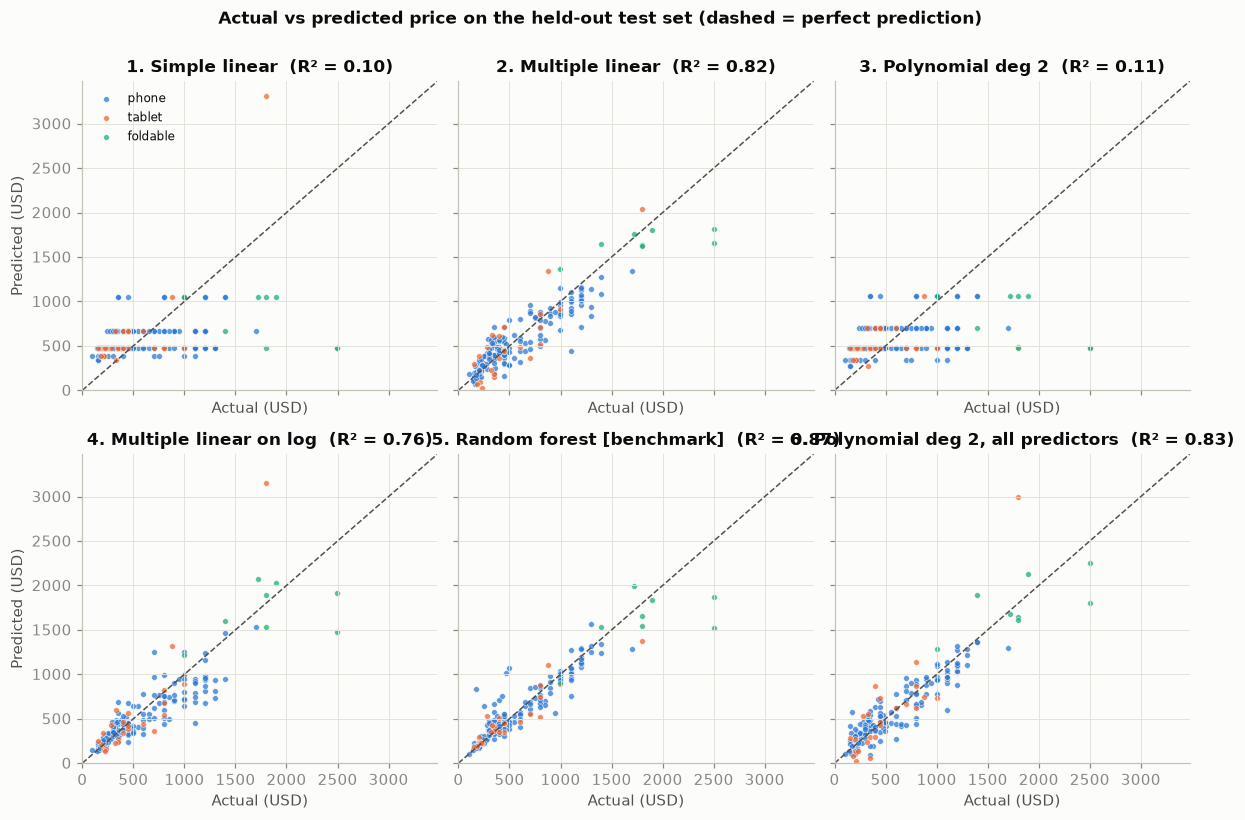

In [31]:
fig, axes = plt.subplots(2, 3, figsize=(11, 7.4), sharex=True, sharey=True); axes = axes.ravel()
lim = [0, max(y_test.max(), max(p.max() for p in test_preds.values())) * 1.05]
for ax, (name, p) in zip(axes, test_preds.items()):
    for t, c in colors.items():
        msk = (X_test["device_type"] == t).values
        ax.scatter(y_test[msk], p[msk], s=14, color=c, alpha=.75, label=t, edgecolors="#fcfcfb", linewidths=.4)
    ax.plot(lim, lim, color=INK2, lw=1, ls="--")
    ax.set(xlim=lim, ylim=lim, title=f"{name.split('(')[0].replace('[ext.]','').strip()}  (R² = {r2_score(y_test, p):.2f})", xlabel="Actual (USD)")
axes[0].set_ylabel("Predicted (USD)"); axes[3].set_ylabel("Predicted (USD)"); axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Actual vs predicted price on the held-out test set (dashed = perfect prediction)", y=1.0, fontsize=11, weight="bold")
plt.tight_layout(); plt.show()

                                            columns  CV RMSE (5-fold, train)  CV RMSE SE
Model                                                                                   
1. Simple linear (storage_gb)                     1                    362.7        13.9
3. Polynomial deg 2 (storage_gb)                  2                    362.0        13.6
2. Multiple linear (all predictors)              37                    200.3         7.5
4. Multiple linear on log(price) [ext.]          37                    212.6        11.3
6. Polynomial deg 2, all predictors [ext.]       92                    185.1         7.9

Lowest CV RMSE: 6. Polynomial deg 2, all predictors [ext.]  ->  1-SE threshold = $193.0
Preferred model (simplest within 1 SE): 6. Polynomial deg 2, all predictors [ext.]


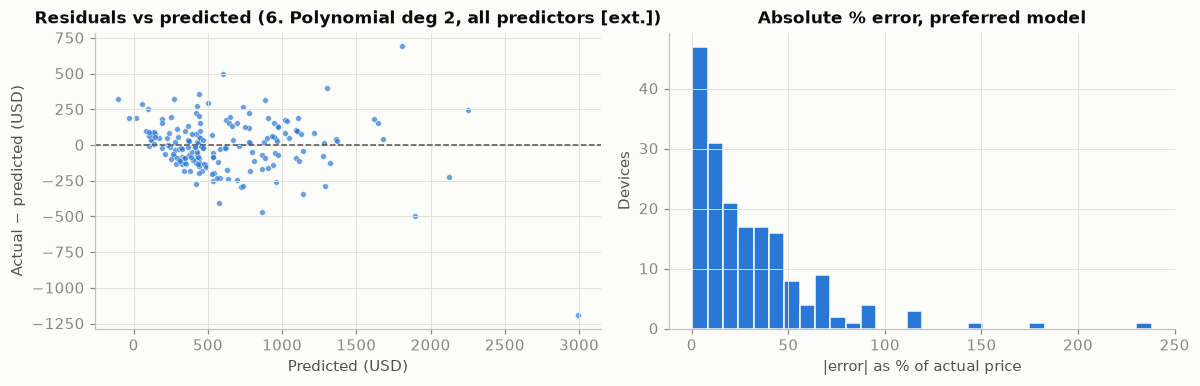

Median absolute % error: 22.5%   |   within ±25%: 55% of test devices

MAE by device type, USD (models 2, 4, 5, 6):
          2. MAE  4. MAE  5. MAE  6. MAE    n
type                                         
foldable   325.0   358.0   320.0   290.0    8
phone      125.0   127.0    87.0   113.0  150
tablet     177.0   175.0    95.0   201.0   25


,brand,model,device_type,actual,predicted,error
96,Apple,iPad Pro 13-inch 2TB,tablet,1799.0,2991.0,-1192.0
634,Huawei,Mate Xs 2,foldable,2499.0,1805.0,694.0
327,Oppo,Find X8 256GB,phone,1099.0,599.0,500.0
165,Samsung,Galaxy W21 5G 256GB,foldable,1399.0,1895.0,-496.0
316,Vivo,Pad 2 256GB,tablet,399.0,867.0,-468.0
417,Oppo,A52 5G 128GB,phone,169.0,572.0,-403.0


In [32]:
# Choosing the preferred model WITHOUT looking at the test set: the "one-standard-error rule".
# Among regression-family models, find the lowest CV RMSE. Then pick the SIMPLEST model whose CV RMSE
# is within one standard error of it. Differences smaller than the fold-to-fold noise are not trusted.
complexity = {"1. Simple linear (storage_gb)": 1, "3. Polynomial deg 2 (storage_gb)": 2,
              "2. Multiple linear (all predictors)": 37, "4. Multiple linear on log(price) [ext.]": 37,
              "6. Polynomial deg 2, all predictors [ext.]": 92}          # number of model columns
cand = res.loc[list(complexity)].assign(columns=pd.Series(complexity))
best = cand["CV RMSE (5-fold, train)"].idxmin()
threshold = cand.loc[best, "CV RMSE (5-fold, train)"] + cand.loc[best, "CV RMSE SE"]
within = cand[cand["CV RMSE (5-fold, train)"] <= threshold].sort_values("columns")
print(cand[["columns", "CV RMSE (5-fold, train)", "CV RMSE SE"]].round(1).to_string())
print(f"\nLowest CV RMSE: {best}  ->  1-SE threshold = ${threshold:,.1f}")
best_linear = within.index[0]
print("Preferred model (simplest within 1 SE):", best_linear)
p = test_preds[best_linear]; resid = y_test - p
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].scatter(p, resid, s=14, color=BLUE, alpha=.7, edgecolors="#fcfcfb", linewidths=.4)
ax[0].axhline(0, color=INK2, lw=1, ls="--")
ax[0].set(title=f"Residuals vs predicted ({best_linear.split('(')[0].strip()})", xlabel="Predicted (USD)", ylabel="Actual − predicted (USD)")
abs_pct = (resid.abs() / y_test * 100)
ax[1].hist(abs_pct, bins=30, color=BLUE, edgecolor="#fcfcfb")
ax[1].set(title="Absolute % error, preferred model", xlabel="|error| as % of actual price", ylabel="Devices")
plt.tight_layout(); plt.show()
print(f"Median absolute % error: {abs_pct.median():.1f}%   |   within ±25%: {(abs_pct <= 25).mean()*100:.0f}% of test devices")

seg = pd.DataFrame({"type": X_test["device_type"]})
for name in ["2. Multiple linear (all predictors)", "4. Multiple linear on log(price) [ext.]", "5. Random forest [benchmark]", "6. Polynomial deg 2, all predictors [ext.]"]:
    seg[name.split(".")[0] + ". MAE"] = (y_test - test_preds[name]).abs()
print("\nMAE by device type, USD (models 2, 4, 5, 6):")
print(seg.groupby("type").agg(["mean"]).round(0).droplevel(1, axis=1).assign(n=seg.groupby("type").size()).to_string())

worst = X_test.assign(model=clean.loc[X_test.index, "model"], actual=y_test, predicted=p.round(0), error=resid.round(0)) \
              .loc[resid.abs().sort_values(ascending=False).index[:6], ["brand", "model", "device_type", "actual", "predicted", "error"]]
worst

### Robustness check: are the scores inflated by storage variants?
`iPhone 16 128GB`, `256GB` and `512GB` are separate rows with identical specs apart from storage. A random split can put one variant in training and its sibling in test, so the model is partly "recognising" a phone it has already seen. **Grouped** cross-validation keeps every variant of a base model in the same fold. This gives a more honest estimate for a *genuinely new* phone.

In [33]:
from sklearn.model_selection import GroupKFold
base_model = clean.loc[X_train.index, "brand"] + " " + clean.loc[X_train.index, "model"].str.replace(r"\s*\d+\s*(GB|TB)$", "", regex=True)
print(f"{len(X_train)} training rows come from {base_model.nunique()} distinct base models")
gkf = GroupKFold(n_splits=5)
rows = []
for name in ["2. Multiple linear (all predictors)", "6. Polynomial deg 2, all predictors [ext.]", "5. Random forest [benchmark]"]:
    feats = NUM_FEATURES + CAT_FEATURES
    g = cross_validate(fitted[name], X_train[feats], y_train, cv=gkf, groups=base_model, scoring=("neg_root_mean_squared_error", "r2"))
    rows.append({"Model": name, "Random 5-fold CV RMSE": res.loc[name, "CV RMSE (5-fold, train)"],
                 "Grouped 5-fold CV RMSE": -g["test_neg_root_mean_squared_error"].mean(), "Grouped CV R²": g["test_r2"].mean()})
grp = pd.DataFrame(rows).set_index("Model"); grp["Increase"] = grp["Grouped 5-fold CV RMSE"] - grp["Random 5-fold CV RMSE"]
grp.round(3)

731 training rows come from 574 distinct base models


,Random 5-fold CV RMSE,Grouped 5-fold CV RMSE,Grouped CV R²,Increase
Model,,,,
2. Multiple linear (all predictors),200.266,205.924,0.748,5.657
"6. Polynomial deg 2, all predictors [ext.]",185.146,192.232,0.780,7.086
5. Random forest [benchmark],154.876,167.548,0.831,12.672


---
## Results summary and preferred model

**Errors in the target's units (USD), test set of 183 devices:**

| Model | Test MAE | Test RMSE | Test R² | Reading |
|---|---|---|---|---|
| 1 Simple linear (storage) | $310 | $427 | 0.10 | Underfits: misses by about half a typical price |
| 3 Polynomial deg 2 (storage) | $309 | $425 | 0.11 | Curve adds almost nothing over model 1 |
| **2 Multiple linear** | **$141** | **$189** | **0.82** | Large improvement, no overfitting |
| 4 MLR on log(price) | $144 | $223 | 0.76 | Better in % terms, worse on expensive devices in USD |
| **6 Poly deg 2, all predictors** | **$133** | **$188** | **0.83** | Best linear-family model, mild overfitting |
| 5 Random forest (benchmark) | $98 | $164 | 0.87 | Most accurate, but outside the scope of the brief |

**How the preferred model was chosen without looking at the test set.** We applied the **one-standard-error rule** to the 5-fold CV results on the *training* data. Model 6 has the lowest CV RMSE ($185 ± 7.9). Model 2 ($200) sits outside the 1-SE band ($193), so the extra flexibility is a genuine gain rather than noise. The test set confirms the ranking only weakly: MAE $133 vs $141, with RMSE practically tied.

**Preferred model: model 6 (degree-2 polynomial on all predictors), with model 2 kept alongside it for explanation.**
* For **prediction**, model 6 is the most accurate regression model. Its typical error is about **$133 per device**, a median miss of **about 22 %** of the true price. About 55 % of test devices are predicted within ±25 %.
* For **explanation**, model 2 is preferred. It has one interpretable coefficient per predictor, while model 6 has 92 terms that cannot be read individually.
* **The trade-off is real.** Model 6 shows a train/test gap and can extrapolate wildly. Its single worst error is the **iPad Pro 13″ 2 TB**, predicted at $2,991 against an actual $1,799. This is the only 2 TB device, and the squared storage term shoots upward outside the range the model has seen. Polynomial models are dangerous outside their training range.

**Key findings**
1. **What a device *is* matters more than its spec sheet.** Device type (phone, tablet or foldable) and brand drive price more than any single hardware number. Specs alone (model 1) explain only about 10 % of the variance, while brand and type lift R² to about 0.8.
2. Among specs, **RAM and storage** carry the strongest signals (about +$55 per GB of RAM, other things equal).
3. **Foldables are the hardest segment:** MAE is about $290–360 across models, versus $113–127 for phones. There are only 38 foldables in the data, and their prices vary widely ($399 Infinix Zero Flip to $2,799 Huawei Mate XT).
4. **Leakage check:** if the Dubai price is included, R² jumps to **0.987**. This confirms that the other-currency prices had to be removed.
5. **Grouped CV** (keeping storage variants of the same phone together) raises RMSE by only about $6–7 for the linear models but by about $13 for the random forest. The linear results are therefore robust. Part of the forest's advantage comes from recognising sibling variants it has already seen.

**Limitations**
* **Target quality.** These are *official launch* prices, not market or resale prices. Several brands (Tecno, Infinix, iQOO, Huawei) are barely sold in the US, so their "USA" prices are probably the uploader's conversions or estimates. This adds noise that no model can remove.
* **Rule-based feature extraction.** Storage parsed from model names (missing for 16 % of rows and imputed), device type from keywords, and chipset families from regex patterns can all mislabel edge cases.
* **Small subgroups.** With only 8 foldables in the test set, segment-level results are unstable. A single random 80:20 split adds variance, which is why we also report CV.
* **Linear assumptions.** Residuals fan out as price rises (heteroscedasticity). This mostly affects confidence intervals, not point predictions, but it means errors on premium devices are much larger than the average suggests.
* **Missing predictors.** Chip performance scores, display technology (OLED vs LCD), materials and marketing positioning are not in the data. They are a likely source of the remaining 17–20 % unexplained variance.

**Possible next steps:** regularised regression (Ridge/Lasso) to stabilise the collinear coefficients and tame model 6; quantile regression to give a price *range* for premium devices; and a benchmark chipset score as a predictor.